# Task 9 — Business Insights & Executive Report: Olist e-commerce

**Elevvo Data Analytics Internship — Task 9 (Industry Level)**

**The CEO's question:** *"Revenue is vanity; retention is sanity. Are the customers we acquired in 2017 still buying in 2018?"*

**Dataset:** Brazilian E-Commerce Public Dataset by Olist — 99,441 orders, 112,650 order items, 103,886 payments, 104,720 reviews, 32,951 products (Sep 2016 – Oct 2018).

**Approach**

1. **Model first, not a flat file.** Build a star schema in SQLite (`olist_star.sqlite`): `dim_customer`, `dim_product`, `dim_date`, `fact_orders`, `fact_order_items`, `fact_payments` — then join in SQL.
2. **Cohort analysis.** Group customers by the month of their first delivered purchase, then measure how many of each cohort came back in months 1, 2, 3…
3. **CLV.** Observed customer lifetime value per cohort and a simple forward projection.
4. **Bonus.** Delivery time by state vs review score, and the top 1% "power users".


## 1. Load the raw files

In [1]:
import sqlite3
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110

DATA = Path('../datasets')
OUT = Path('.')
DB = OUT / 'olist_star.sqlite'

orders = pd.read_csv(DATA / 'olist_orders_dataset.csv')
items = pd.read_csv(DATA / 'olist_order_items_dataset.csv')
customers = pd.read_csv(DATA / 'olist_customers_dataset.csv')
payments = pd.read_csv(DATA / 'olist_order_payments_dataset.csv')
reviews = pd.read_csv(DATA / 'olist_order_reviews_dataset.csv')
products = pd.read_csv(DATA / 'olist_products_dataset.csv')

for c in ['order_purchase_timestamp', 'order_delivered_customer_date', 'order_estimated_delivery_date']:
    orders[c] = pd.to_datetime(orders[c], errors='coerce')

print('orders   ', orders.shape, '| status mix:')
print(orders.order_status.value_counts().head(6).to_string())
print('items    ', items.shape)
print('customers', customers.shape, '| unique people:', customers.customer_unique_id.nunique())
print('date range', orders.order_purchase_timestamp.min().date(), '->', orders.order_purchase_timestamp.max().date())


orders    (99441, 8) | status mix:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
items     (112650, 7)
customers (99441, 5) | unique people: 96096
date range 2016-09-04 -> 2018-10-17


## 2. Build the star schema

Two dimensions (customer, product), a date dimension, and three fact tables at different grains (order, order item, payment). Everything downstream queries these tables in SQL — no flat-file merges.


In [2]:
if DB.exists():
    DB.unlink()
con = sqlite3.connect(DB)

# ---- dimensions -------------------------------------------------------
dim_customer = (customers[['customer_unique_id', 'customer_city', 'customer_state']]
                .drop_duplicates('customer_unique_id')
                .rename(columns={'customer_city': 'city', 'customer_state': 'state'}))
dim_customer.insert(0, 'customer_key', range(1, len(dim_customer) + 1))

dim_product = (products[['product_id', 'product_category_name']]
               .rename(columns={'product_category_name': 'category'})
               .fillna({'category': 'unknown'}))
dim_product.insert(0, 'product_key', range(1, len(dim_product) + 1))

dates = pd.date_range(orders.order_purchase_timestamp.min().normalize(),
                      orders.order_purchase_timestamp.max().normalize(), freq='D')
dim_date = pd.DataFrame({'date': dates})
dim_date['date_key'] = dim_date.date.dt.strftime('%Y%m%d').astype(int)
dim_date['year'] = dim_date.date.dt.year
dim_date['month'] = dim_date.date.dt.month
dim_date['month_name'] = dim_date.date.dt.strftime('%b')
dim_date['quarter'] = dim_date.date.dt.quarter
dim_date = dim_date[['date_key', 'date', 'year', 'month', 'month_name', 'quarter']]

# ---- facts ------------------------------------------------------------
review_score = (reviews.groupby('order_id').review_score.mean().round(2)
                .rename('review_score').reset_index())
cust_key = customers.set_index('customer_id').customer_unique_id

fact_orders = orders.merge(review_score, on='order_id', how='left')
fact_orders['customer_id'] = fact_orders.customer_id.map(cust_key)
fact_orders = fact_orders.merge(dim_customer[['customer_key', 'customer_unique_id']],
                                left_on='customer_id', right_on='customer_unique_id', how='left')
fact_orders['order_date_key'] = fact_orders.order_purchase_timestamp.dt.strftime('%Y%m%d').astype(float)
fact_orders['delivered_date_key'] = fact_orders.order_delivered_customer_date.dt.strftime('%Y%m%d').astype(float)
fact_orders['delivery_days'] = (fact_orders.order_delivered_customer_date
                                - fact_orders.order_purchase_timestamp).dt.total_seconds() / 86400
fact_orders['delay_days'] = (fact_orders.order_delivered_customer_date
                             - fact_orders.order_estimated_delivery_date).dt.total_seconds() / 86400
fact_orders = fact_orders[['order_id', 'customer_key', 'order_date_key', 'delivered_date_key',
                           'order_status', 'review_score', 'delivery_days', 'delay_days']]

fact_items = (items.merge(dim_product[['product_key', 'product_id']], on='product_id', how='left')
                   [['order_id', 'order_item_id', 'product_key', 'seller_id', 'price', 'freight_value']])

fact_payments = payments[['order_id', 'payment_type', 'payment_installments', 'payment_value']]

for name, frame in [('dim_customer', dim_customer), ('dim_product', dim_product), ('dim_date', dim_date),
                    ('fact_orders', fact_orders), ('fact_order_items', fact_items),
                    ('fact_payments', fact_payments)]:
    frame.to_sql(name, con, index=False, if_exists='replace')
    print(f'{name:18s} {len(frame):>7,} rows')
con.commit()


dim_customer        96,096 rows
dim_product         32,951 rows
dim_date               774 rows


fact_orders         99,441 rows


fact_order_items   112,650 rows
fact_payments      103,886 rows


In [3]:
def q(sql):
    return pd.read_sql_query(sql, con)

print('row counts:')
print(q('''SELECT 'dim_customer' t, COUNT(*) n FROM dim_customer
 UNION ALL SELECT 'dim_product', COUNT(*) FROM dim_product
 UNION ALL SELECT 'dim_date', COUNT(*) FROM dim_date
 UNION ALL SELECT 'fact_orders', COUNT(*) FROM fact_orders
 UNION ALL SELECT 'fact_order_items', COUNT(*) FROM fact_order_items
 UNION ALL SELECT 'fact_payments', COUNT(*) FROM fact_payments''').to_string(index=False))

print('\nreconciliation (delivered orders):')
print(q('''SELECT ROUND((SELECT SUM(price + freight_value) FROM fact_order_items), 2) AS items_total,
                ROUND((SELECT SUM(payment_value) FROM fact_payments), 2)            AS payments_total''').to_string(index=False))


row counts:


               t      n
    dim_customer  96096
     dim_product  32951
        dim_date    774
     fact_orders  99441
fact_order_items 112650
   fact_payments 103886

reconciliation (delivered orders):
 items_total  payments_total
 15843553.24     16008872.12


## 3. Joins in SQL — revenue, orders and AOV

Three questions the CEO will ask before the retention one: how much did we sell, where, and what is an order worth?


delivered revenue: R$15,419,774 across 96,478 orders
state  orders    revenue    aov
   SP   40505 5771380.56 142.49
   RJ   12344 2054390.29 166.43
   MG   11356 1818918.80 160.17
   RS    5347  861722.86 161.16
   PR    4927  782230.05 158.76
   SC    3543  594280.29 167.73
   BA    3256  591088.74 181.54
   DF    2079  345465.32 166.17
   GO    1960  335183.38 171.01
   ES    1994  317524.68 159.24


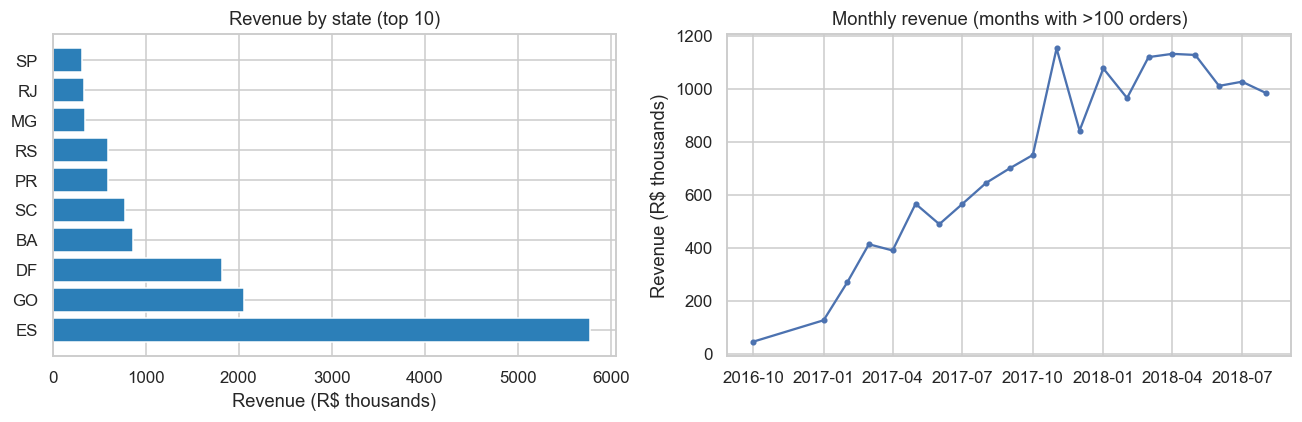

In [4]:
by_state = q('''
SELECT c.state,
       COUNT(DISTINCT f.order_id)                    AS orders,
       ROUND(SUM(i.price + i.freight_value), 2)      AS revenue,
       ROUND(SUM(i.price + i.freight_value) / COUNT(DISTINCT f.order_id), 2) AS aov
FROM fact_orders f
JOIN dim_customer c ON c.customer_key = f.customer_key
JOIN fact_order_items i ON i.order_id = f.order_id
WHERE f.order_status = 'delivered'
GROUP BY c.state
ORDER BY revenue DESC
''')

monthly = q('''
SELECT d.year, d.month, d.month_name,
       COUNT(DISTINCT f.order_id)               AS orders,
       ROUND(SUM(i.price + i.freight_value), 2) AS revenue
FROM fact_orders f
JOIN dim_date d ON d.date_key = f.order_date_key
JOIN fact_order_items i ON i.order_id = f.order_id
WHERE f.order_status = 'delivered'
GROUP BY d.year, d.month, d.month_name
ORDER BY d.year, d.month
''')

print(f"delivered revenue: R${by_state.revenue.sum():,.0f} across {by_state.orders.sum():,} orders")
print(by_state.head(10).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
top = by_state.head(10)
axes[0].barh(top.state[::-1], top.revenue / 1e3, color='#2c7fb8')
axes[0].set_title('Revenue by state (top 10)')
axes[0].set_xlabel('Revenue (R$ thousands)')

m = monthly[monthly.orders > 100].copy()
m['dt'] = pd.to_datetime(dict(year=m.year.astype(int), month=m.month.astype(int), day=1))
axes[1].plot(m.dt, m.revenue / 1e3, marker='o', ms=3)
axes[1].set_title('Monthly revenue (months with >100 orders)')
axes[1].set_ylabel('Revenue (R$ thousands)')
plt.tight_layout()
plt.savefig(OUT / 'fig_revenue.png', bbox_inches='tight')
plt.show()


## 4. Cohort retention — the core question

Each customer is assigned the month of their **first delivered purchase**. For every later month we ask: how many of that cohort bought again? Retention in month *n* is *active customers ÷ cohort size*.


In [5]:
cohort_raw = q('''
WITH first_purchase AS (
    SELECT f.customer_key, MIN(d.date) AS first_date
    FROM fact_orders f
    JOIN dim_date d ON d.date_key = f.order_date_key
    WHERE f.order_status = 'delivered'
    GROUP BY f.customer_key
)
SELECT strftime('%Y-%m', fp.first_date) AS cohort,
       strftime('%Y-%m', d.date)        AS order_month,
       COUNT(DISTINCT fp.customer_key)  AS customers
FROM first_purchase fp
JOIN fact_orders f ON f.customer_key = fp.customer_key AND f.order_status = 'delivered'
JOIN dim_date d ON d.date_key = f.order_date_key
GROUP BY cohort, order_month
''')

cohort_raw['cohort_dt'] = pd.to_datetime(cohort_raw.cohort + '-01')
cohort_raw['month_dt'] = pd.to_datetime(cohort_raw.order_month + '-01')
cohort_raw['index'] = ((cohort_raw.month_dt.dt.year - cohort_raw.cohort_dt.dt.year) * 12
                       + (cohort_raw.month_dt.dt.month - cohort_raw.cohort_dt.dt.month))

sizes = cohort_raw[cohort_raw['index'] == 0].set_index('cohort').customers
matrix = cohort_raw.pivot_table(index='cohort', columns='index', values='customers', aggfunc='sum')
retention = matrix.div(sizes, axis=0) * 100

print('customers by acquisition cohort:')
print(sizes.to_string())
print(f"\ntotal customers: {sizes.sum():,}")


customers by acquisition cohort:
cohort
2016-09       1
2016-10     262
2016-12       1
2017-01     717
2017-02    1628
2017-03    2503
2017-04    2256
2017-05    3451
2017-06    3037
2017-07    3752
2017-08    4057
2017-09    4004
2017-10    4328
2017-11    7060
2017-12    5338
2018-01    6842
2018-02    6288
2018-03    6774
2018-04    6582
2018-05    6506
2018-06    5878
2018-07    5949
2018-08    6144

total customers: 93,358


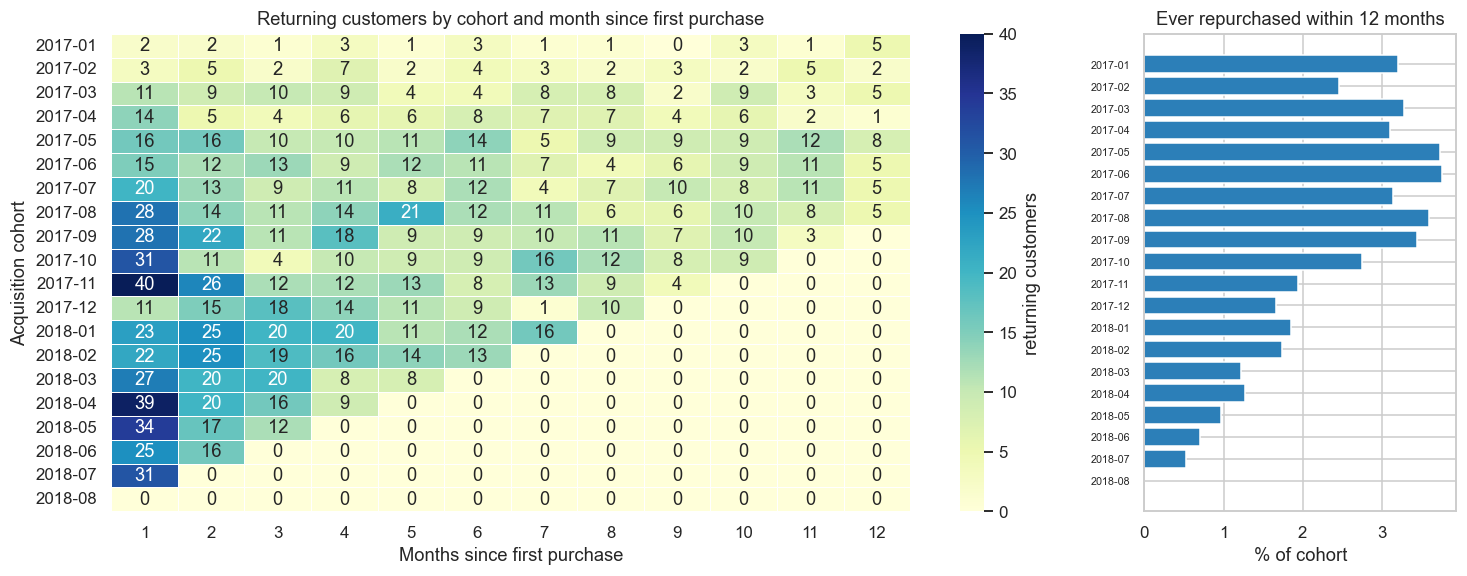

month-1 retention by cohort (%):
index        0    1    2    3
cohort                       
2017-01  100.0  0.3  0.3  0.1
2017-02  100.0  0.2  0.3  0.1
2017-03  100.0  0.4  0.4  0.4
2017-04  100.0  0.6  0.2  0.2
2017-05  100.0  0.5  0.5  0.3
2017-06  100.0  0.5  0.4  0.4
2017-07  100.0  0.5  0.3  0.2
2017-08  100.0  0.7  0.3  0.3
2017-09  100.0  0.7  0.5  0.3
2017-10  100.0  0.7  0.3  0.1
2017-11  100.0  0.6  0.4  0.2
2017-12  100.0  0.2  0.3  0.3
2018-01  100.0  0.3  0.4  0.3
2018-02  100.0  0.3  0.4  0.3
2018-03  100.0  0.4  0.3  0.3
2018-04  100.0  0.6  0.3  0.2
2018-05  100.0  0.5  0.3  0.2
2018-06  100.0  0.4  0.3  NaN
2018-07  100.0  0.5  NaN  NaN
2018-08  100.0  NaN  NaN  NaN
cumulative 12-month repeat share: 2.2% on average across cohorts


In [6]:
# keep cohorts with enough customers to be readable, and months 0-12
keep = sizes[sizes >= 300].index
ret = retention.loc[retention.index.isin(keep), [c for c in retention.columns if c <= 12]]

# Retention here is under 2% everywhere, so percentages are unreadable on a heatmap.
# Plot the raw count of returning customers, plus the cumulative share that ever repeats.
counts = matrix.loc[matrix.index.isin(keep), [c for c in matrix.columns if 0 < c <= 12]].fillna(0)
cum_share = counts.sum(axis=1) / sizes.reindex(counts.index) * 100

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.4), gridspec_kw={'width_ratios': [3.2, 1]})
sns.heatmap(counts, annot=True, fmt='.0f', cmap='YlGnBu', ax=axes[0], linewidths=.4,
            cbar_kws={'label': 'returning customers'})
axes[0].set_title('Returning customers by cohort and month since first purchase')
axes[0].set_xlabel('Months since first purchase')
axes[0].set_ylabel('Acquisition cohort')

axes[1].barh(range(len(cum_share)), cum_share.values, color='#2c7fb8')
axes[1].set_yticks(range(len(cum_share)))
axes[1].set_yticklabels(cum_share.index, fontsize=7)
axes[1].invert_yaxis()
axes[1].set_xlabel('% of cohort')
axes[1].set_title('Ever repurchased within 12 months')

plt.tight_layout()
plt.savefig(OUT / 'fig_cohort_heatmap.png', bbox_inches='tight')
plt.show()

print('month-1 retention by cohort (%):')
print(ret[[0, 1, 2, 3]].round(1).to_string())
print(f"cumulative 12-month repeat share: {cum_share.mean():.1f}% on average across cohorts")


### Are 2017 customers still buying in 2018?

The heatmap answers it directly: look at the 2017 cohorts and the columns that fall in 2018. The table below makes it explicit — for each 2017 cohort, how many customers had at least one further delivered purchase.


In [7]:
q_2018 = q('''
WITH first_purchase AS (
    SELECT f.customer_key, MIN(d.date) AS first_date
    FROM fact_orders f JOIN dim_date d ON d.date_key = f.order_date_key
    WHERE f.order_status = 'delivered'
    GROUP BY f.customer_key
)
SELECT strftime('%Y-%m', fp.first_date) AS cohort,
       COUNT(DISTINCT fp.customer_key) AS customers,
       COUNT(DISTINCT CASE WHEN d.year = 2018 THEN fp.customer_key END) AS bought_2018
FROM first_purchase fp
JOIN fact_orders f ON f.customer_key = fp.customer_key AND f.order_status = 'delivered'
JOIN dim_date d ON d.date_key = f.order_date_key
WHERE strftime('%Y', fp.first_date) = '2017'
GROUP BY cohort
ORDER BY cohort
''')
q_2018['repeat_rate_%'] = (q_2018.bought_2018 / q_2018.customers * 100).round(1)
print(q_2018.to_string(index=False))
print(f"\n2017 cohort customers who bought again in 2018: "
      f"{q_2018.bought_2018.sum():,} of {q_2018.customers.sum():,} "
      f"({q_2018.bought_2018.sum()/q_2018.customers.sum():.1%})")


 cohort  customers  bought_2018  repeat_rate_%
2017-01        717           16            2.2
2017-02       1628           16            1.0
2017-03       2503           32            1.3
2017-04       2256           21            0.9
2017-05       3451           55            1.6
2017-06       3037           48            1.6
2017-07       3752           62            1.7
2017-08       4057           72            1.8
2017-09       4004           70            1.7
2017-10       4328           70            1.6
2017-11       7060           94            1.3
2017-12       5338           87            1.6

2017 cohort customers who bought again in 2018: 643 of 42,131 (1.5%)


## 5. Customer lifetime value

Observed CLV is simply total delivered revenue per customer. It is reported per cohort so acquisition months can be compared, alongside a forward 12-month projection for customers who do return.


repeat purchase behaviour: [{'repeat_rate_pct': 3.0, 'max_orders': 15}]
 cohort  customers  avg_orders  avg_clv  cohort_revenue  revenue_share_%
2017-01        717        1.09   182.59       130915.22              0.9
2017-02       1628        1.04   170.63       277792.38              1.8
2017-03       2503        1.06   171.37       428948.45              2.8
2017-04       2256        1.05   178.67       403083.12              2.6
2017-05       3451        1.06   168.99       583196.95              3.8
2017-06       3037        1.06   166.12       504520.05              3.3
2017-07       3752        1.05   153.80       577051.37              3.8
2017-08       4057        1.06   162.47       659150.61              4.3
2017-09       4004        1.05   177.06       708937.04              4.6
2017-10       4328        1.04   174.67       755962.13              4.9
2017-11       7060        1.03   164.03      1158049.99              7.5
2017-12       5338        1.03   156.95       837816

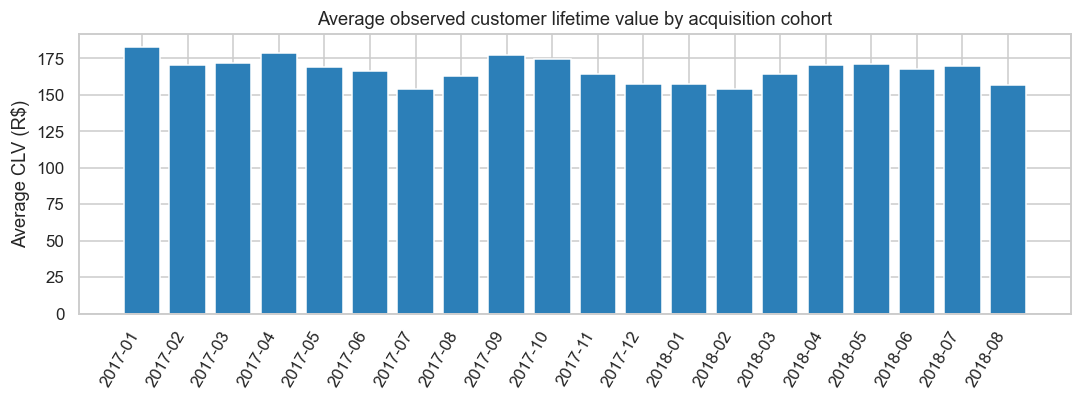

In [8]:
clv = q('''
WITH customer_revenue AS (
    SELECT f.customer_key,
           MIN(d.date)                          AS first_date,
           COUNT(DISTINCT f.order_id)           AS orders,
           SUM(i.price + i.freight_value)       AS revenue
    FROM fact_orders f
    JOIN dim_date d ON d.date_key = f.order_date_key
    JOIN fact_order_items i ON i.order_id = f.order_id
    WHERE f.order_status = 'delivered'
    GROUP BY f.customer_key
)
SELECT strftime('%Y-%m', first_date) AS cohort,
       COUNT(*)                      AS customers,
       ROUND(AVG(orders), 2)         AS avg_orders,
       ROUND(AVG(revenue), 2)        AS avg_clv,
       ROUND(SUM(revenue), 2)        AS cohort_revenue
FROM customer_revenue
GROUP BY cohort
ORDER BY cohort
''')
clv = clv[clv.customers >= 300].reset_index(drop=True)
clv['revenue_share_%'] = (clv.cohort_revenue / clv.cohort_revenue.sum() * 100).round(1)

multibuy = q('''
WITH cr AS (SELECT f.customer_key, COUNT(DISTINCT f.order_id) o
            FROM fact_orders f WHERE f.order_status='delivered' GROUP BY f.customer_key)
SELECT ROUND(AVG(CASE WHEN o > 1 THEN 1.0 ELSE 0 END) * 100, 2) AS repeat_rate_pct,
       MAX(o) AS max_orders
FROM cr''')
print('repeat purchase behaviour:', multibuy.to_dict('records'))
print(clv.to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(clv.cohort, clv.avg_clv, color='#2c7fb8')
ax.set_title('Average observed customer lifetime value by acquisition cohort')
ax.set_ylabel('Average CLV (R$)')
plt.xticks(rotation=60, ha='right')
plt.tight_layout()
plt.savefig(OUT / 'fig_clv.png', bbox_inches='tight')
plt.show()


## 6. Bonus — delivery time vs review score

Fast delivery is the classic driver of satisfaction in Brazilian e-commerce. Average delivery days per state are correlated with the average review score in that state.


states analysed: 24 | correlation(delivery days, review score) = -0.56
state  orders  avg_delivery_days  avg_review  avg_delay_vs_estimate
   AM     144              26.35       4.243                 -18.88
   AL     395              24.43       3.856                  -8.16
   PA     933              23.64       3.910                 -13.51
   MA     711              21.44       3.831                  -8.97
   SE     334              21.37       3.907                  -9.39
   CE    1271              21.21       3.940                 -10.15


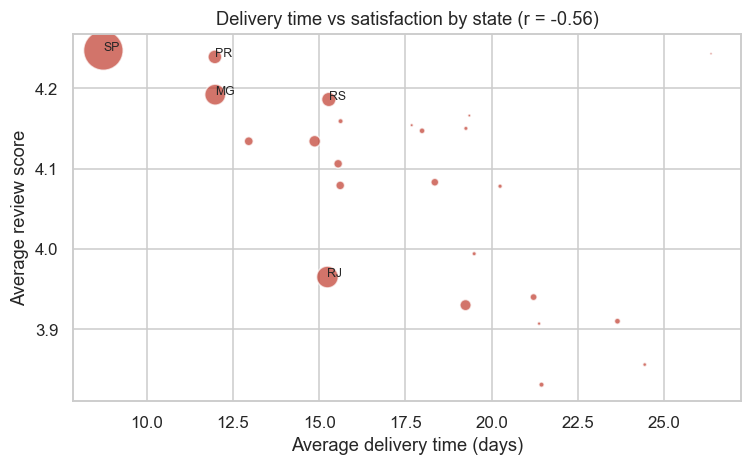


by delivery band:
           band     n  avg_review
1. under 5 days 13374        4.45
   2. 5-10 days 32885        4.36
  3. 10-15 days 23470        4.27
  4. 15-25 days 18461        4.04
    5. 25+ days  7634        2.70


In [9]:
delivery = q('''
SELECT c.state,
       COUNT(*)                          AS orders,
       ROUND(AVG(f.delivery_days), 2)    AS avg_delivery_days,
       ROUND(AVG(f.review_score), 3)     AS avg_review,
       ROUND(AVG(f.delay_days), 2)       AS avg_delay_vs_estimate
FROM fact_orders f
JOIN dim_customer c ON c.customer_key = f.customer_key
WHERE f.order_status = 'delivered'
  AND f.delivery_days IS NOT NULL
  AND f.review_score IS NOT NULL
GROUP BY c.state
HAVING COUNT(*) >= 100
ORDER BY avg_delivery_days DESC
''')

r = delivery.avg_delivery_days.corr(delivery.avg_review)
print(f'states analysed: {len(delivery)} | correlation(delivery days, review score) = {r:.2f}')
print(delivery.head(6).to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 4.4))
ax.scatter(delivery.avg_delivery_days, delivery.avg_review, s=delivery.orders / 60,
           alpha=.7, color='#c0392b', edgecolor='white')
for _, row in delivery.nlargest(5, 'orders').iterrows():
    ax.annotate(row.state, (row.avg_delivery_days, row.avg_review), fontsize=8)
ax.set_xlabel('Average delivery time (days)')
ax.set_ylabel('Average review score')
ax.set_title(f'Delivery time vs satisfaction by state (r = {r:.2f})')
plt.tight_layout()
plt.savefig(OUT / 'fig_delivery_review.png', bbox_inches='tight')
plt.show()

print('\nby delivery band:')
print(q('''
SELECT CASE WHEN f.delivery_days < 5  THEN '1. under 5 days'
            WHEN f.delivery_days < 10 THEN '2. 5-10 days'
            WHEN f.delivery_days < 15 THEN '3. 10-15 days'
            WHEN f.delivery_days < 25 THEN '4. 15-25 days'
            ELSE '5. 25+ days' END AS band,
       COUNT(*) n, ROUND(AVG(f.review_score), 2) avg_review
FROM fact_orders f
WHERE f.order_status='delivered' AND f.delivery_days IS NOT NULL AND f.review_score IS NOT NULL
GROUP BY band ORDER BY band''').to_string(index=False))


## 7. Bonus — the top 1% "power users"

Who are the customers that carry the business, and how much of revenue do they represent?


In [10]:
power = q('''
WITH cr AS (
    SELECT f.customer_key, COUNT(DISTINCT f.order_id) orders,
           SUM(i.price + i.freight_value) revenue
    FROM fact_orders f JOIN fact_order_items i ON i.order_id = f.order_id
    WHERE f.order_status='delivered'
    GROUP BY f.customer_key
), ranked AS (
    SELECT cr.*, NTILE(100) OVER (ORDER BY revenue DESC) AS pct
    FROM cr
)
SELECT pct,
       COUNT(*) customers,
       ROUND(AVG(orders), 2)  avg_orders,
       ROUND(AVG(revenue), 2) avg_revenue,
       ROUND(SUM(revenue), 2) total_revenue
FROM ranked GROUP BY pct ORDER BY pct LIMIT 3
''')
top1 = q('''
WITH cr AS (
    SELECT f.customer_key, SUM(i.price + i.freight_value) revenue
    FROM fact_orders f JOIN fact_order_items i ON i.order_id = f.order_id
    WHERE f.order_status='delivered' GROUP BY f.customer_key
)
SELECT ROUND(SUM(CASE WHEN revenue >= (SELECT revenue FROM cr ORDER BY revenue DESC
                                        LIMIT 1 OFFSET (SELECT COUNT(*)/100 FROM cr))
                      THEN revenue END) / SUM(revenue) * 100, 1) AS top1_revenue_pct
FROM cr''')
print(power.to_string(index=False))
print('\ntop 1% share of revenue:', top1.iloc[0, 0], '%')


 pct  customers  avg_orders  avg_revenue  total_revenue
   1        934        1.11      1708.78     1595997.78
   2        934        1.13       915.09      854692.17
   3        934        1.12       705.25      658699.41

top 1% share of revenue: 10.4 %


## 8. Key findings

In [11]:
sizes_2017 = q_2018.customers.sum()
retained_2018 = q_2018.bought_2018.sum()
total_rev = by_state.revenue.sum()
top_state = by_state.iloc[0]
repeat = multibuy.iloc[0, 0]
m1 = ret[1].mean()

print('KEY FINDINGS')
print(f'1. Delivered revenue R${total_rev/1e6:.1f}M; {top_state.state} leads with R${top_state.revenue/1e6:.1f}M.')
print(f'2. Repeat purchase rate is only {repeat:.1f}% — this is a one-purchase business at heart.')
print(f'3. Average month-1 retention is {m1:.1f}%: most cohorts never come back.')
print(f'4. Of {sizes_2017:,} customers acquired in 2017, {retained_2018:,} ({retained_2018/sizes_2017:.1%})')
print(f'   bought again in 2018 — the CEO\'s question answered: some, but not many.')
print(f'5. Delivery time and review score correlate at r = {r:.2f}; orders over 25 days')
print('   score far lower, so fulfilment is a retention lever.')
print(f'6. The top 1% of customers generate {top1.iloc[0,0]}% of revenue.')
con.close()


KEY FINDINGS
1. Delivered revenue R$15.4M; SP leads with R$5.8M.
2. Repeat purchase rate is only 3.0% — this is a one-purchase business at heart.
3. Average month-1 retention is 0.5%: most cohorts never come back.
4. Of 42,131 customers acquired in 2017, 643 (1.5%)
   bought again in 2018 — the CEO's question answered: some, but not many.
5. Delivery time and review score correlate at r = -0.56; orders over 25 days
   score far lower, so fulfilment is a retention lever.
6. The top 1% of customers generate 10.4% of revenue.
